# Chimera v2.4 -- Validation & Ablation Analysis

This notebook runs the full validation and ablation suite for Chimera v2.4,
producing all comparison tables and supplementary figures for the manuscript.

**Sections:**
1. **Baseline Ladder** -- Train or load scVI, Harmony, scANVI baselines and Chimera configs; compute scIB metrics and cross-species label transfer.
2. **Ablation Suite** -- Train all priority ablation configurations (A, D, F, M, J, C, H, B') and compare.
3. **Alpha Analysis** -- Examine alpha distributions, delta-alpha two-sidedness across configs.
4. **Stress Tests** -- Gene dropout and conservation-prior shuffle robustness checks.
5. **scVI Post-hoc Comparison** -- Correlate Chimera alpha with scVI-derived per-gene F-statistics.

**Prerequisites:**
- Notebook `01_data_preparation` has been run (prepared AnnData saved to disk).
- Notebook `02_training` has been run (trained Chimera model checkpoint available).

**Expected runtime:** ~8--12 hours for the full ablation suite on a single A100 GPU.  
Individual sections can be run independently if checkpoints are available.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from scipy.stats import spearmanr

# Chimera imports
sys.path.insert(0, str(Path(".").resolve().parent))
from chimera._model import ChimeraModel
from chimera._constants import ABLATION_CONFIGS
from scripts.train_baselines import (
    train_baseline_ladder,
    compute_scvi_f_statistics,
    compare_fstats_with_alpha,
)
from scripts.compute_metrics import (
    compute_all_metrics,
    cross_species_label_transfer,
    _compute_scib_metrics,
)
from scripts.run_ablations import run_ablation_suite, run_single_ablation

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="scvi")

# Plotting defaults
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "figure.figsize": (8, 5),
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.1,
})
sns.set_style("whitegrid")

# Paths
DATA_DIR = Path("..") / "data"
RESULTS_DIR = Path("..") / "results" / "validation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_DIR = RESULTS_DIR / "baselines"
BASELINE_DIR.mkdir(parents=True, exist_ok=True)
ABLATION_DIR = RESULTS_DIR / "ablations"
ABLATION_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = RESULTS_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DATASET_NAME = "camex_pancreas"
ADATA_PATH = DATA_DIR / "processed" / f"{DATASET_NAME}_unified.h5ad"

SEED = 42
MAX_EPOCHS = 200

print(f"Data path:    {ADATA_PATH}")
print(f"Results dir:  {RESULTS_DIR}")
print(f"Seed:         {SEED}")
print(f"Max epochs:   {MAX_EPOCHS}")

Data path:    ../data/processed/camex_pancreas_unified.h5ad
Results dir:  ../results/validation
Seed:         42
Max epochs:   200


In [2]:
adata = ad.read_h5ad(ADATA_PATH)
print(f"Loaded AnnData: {adata.n_obs} cells x {adata.n_vars} genes")
print(f"Species: {adata.obs['species'].value_counts().to_dict()}")
print(f"Cell types: {adata.obs['cell_type'].nunique()} unique")
print(f"Batches: {adata.obs['batch'].nunique()} unique")
print(f"Gene features shape: {adata.varm['gene_features'].shape}")
print(f"Conservation prior range: [{adata.var['conservation_prior'].min():.3f}, {adata.var['conservation_prior'].max():.3f}]")

Loaded AnnData: 22104 cells x 8879 genes
Species: {'Monkey': 8483, 'Zebrafish': 5530, 'Human': 4125, 'Mouse': 3966}
Cell types: 9 unique
Batches: 5 unique
Gene features shape: (8879, 72)
Conservation prior range: [0.164, 0.950]


---
## Section 1: Baseline Ladder

Train or load baseline methods (scVI, Harmony, scANVI) alongside Chimera ablation
configs D and F.  Compute the full scIB metric suite plus cross-species label
transfer accuracy for all methods.

In [3]:
# Train baselines (or load from checkpoints if they exist)
baseline_results_path = BASELINE_DIR / "training_results.json"
adata_with_latents_path = BASELINE_DIR / "adata_with_latents.h5ad"

if adata_with_latents_path.exists():
    print("Loading pre-computed baseline results ...")
    adata_eval = ad.read_h5ad(adata_with_latents_path)
    with open(baseline_results_path) as f:
        baseline_results = json.load(f)
    print(f"Loaded: {list(baseline_results.keys())}")
else:
    print("Training baseline ladder from scratch (this may take several hours) ...")
    baseline_results = train_baseline_ladder(
        dataset_path=str(ADATA_PATH),
        output_dir=str(BASELINE_DIR),
        seed=SEED,
        max_epochs=MAX_EPOCHS,
        wandb_project="chimera-validation",
    )
    adata_eval = ad.read_h5ad(adata_with_latents_path)
    print(f"Baselines trained: {list(baseline_results.keys())}")

# List available latent representations
latent_keys = [k for k in adata_eval.obsm.keys() if k.startswith("X_")]
print(f"Available latent keys: {latent_keys}")

Training baseline ladder from scratch (this may take several hours) ...


2026-04-19 06:38:44,794 [INFO] scripts.train_baselines: Loading dataset from ../data/processed/camex_pancreas_unified.h5ad


2026-04-19 06:38:44,851 [INFO] scripts.train_baselines: Dataset: 22104 cells x 8879 genes


2026-04-19 06:38:48,195 [WARNING] scripts.train_baselines: wandb unavailable or init failed (No API key configured. Use `wandb login` to log in.); skipping logging.


2026-04-19 06:38:48,197 [INFO] scripts.train_baselines: === Training scVI (species-as-batch) ===


2026-04-19 06:38:48,284 [WARNING] urllib3.connectionpool: Retrying (Retry(total=2, connect=None, read=None, redirect=None, status=None)) after connection broken by 'SSLError(SSLCertVerificationError(1, '[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: self-signed certificate (_ssl.c:1007)'))': /api/4504800232407040/envelope/


... (88 outputs left out)

2026-04-19 09:18:02,126 [INFO] scripts.train_baselines: F-stat vs alpha Spearman: r=0.2232, p=1.20e-100


2026-04-19 09:18:02,306 [INFO] scripts.train_baselines: AnnData with latent representations saved to ../results/validation/baselines/adata_with_latents.h5ad


2026-04-19 09:18:02,307 [INFO] scripts.train_baselines: Results summary saved to ../results/validation/baselines/training_results.json


Baselines trained: ['scVI', 'Harmony', 'scANVI', 'Chimera_D', 'Chimera_F', 'fstat_alpha_comparison']
Available latent keys: ['X_Chimera_D', 'X_Chimera_F', 'X_Harmony', 'X_scANVI', 'X_scVI']


In [4]:
# Compute the full scIB metric suite for every latent representation
metrics_csv_path = RESULTS_DIR / "baseline_comparison.csv"

if metrics_csv_path.exists():
    print("Loading pre-computed metrics ...")
    comparison_table = pd.read_csv(metrics_csv_path)
else:
    print("Computing metrics for all methods ...")
    comparison_table = compute_all_metrics(
        adata_path=str(adata_with_latents_path),
        latent_keys=latent_keys,
        output_path=str(metrics_csv_path),
        batch_key="species",
        label_key="cell_type",
    )

# Clean up method names for display
comparison_table["method"] = comparison_table["method"].str.replace("X_", "")
print(comparison_table.to_string(index=False))

2026-04-19 09:18:02,420 [INFO] scripts.compute_metrics: Loading AnnData from ../results/validation/baselines/adata_with_latents.h5ad


2026-04-19 09:18:02,479 [INFO] scripts.compute_metrics: AnnData: 22104 cells x 8879 genes


2026-04-19 09:18:02,479 [INFO] scripts.compute_metrics: --- Evaluating: X_Chimera_D ---


Computing metrics for all methods ...


2026-04-19 09:18:25,366 [WARNING] scripts.compute_metrics: scib metric kBET failed: 
'rpy2' is an optional dependency and not installed by default. Please make sure you install it manually.


mean silhouette per group:                 silhouette_score
group                           
B Plasma cells          0.590035
Cholangio               0.623349
Endothelial             0.601270
Hepatocytes             0.504663
Kupffer cells           0.425082
Macrophages             0.309801
fibroblasts             0.554851


... (67 outputs left out)

2026-04-19 09:20:31,793 [INFO] scripts.compute_metrics: Cross-species label transfer mean accuracy: 0.8350


2026-04-19 09:20:31,810 [INFO] scripts.compute_metrics: Metric comparison table saved to ../results/validation/baseline_comparison.csv


2026-04-19 09:20:31,812 [INFO] scripts.compute_metrics: 
     method  batch_ASW  kBET  graph_connectivity  iLISI  cell_type_ASW      NMI      ARI  isolated_label_ASW  cLISI  cross_species_transfer_acc  transfer_Human  transfer_Monkey  transfer_Mouse  transfer_Zebrafish
X_Chimera_D   0.515579   NaN            0.727487    NaN       0.580190 0.421655 0.071688            0.681535    NaN                    0.705540        0.955394         0.934935        0.920619            0.011212
X_Chimera_F   0.497146   NaN            0.707665    NaN       0.584581 0.436068 0.086682            0.702525    NaN                    0.799766        0.936727         0.836311        0.868882            0.557143
  X_Harmony   0.805539   NaN            0.859580    NaN       0.461223 0.574300 0.251635            0.529578    NaN                    0.915654        0.932848         0.822549        0.950799            0.956420
   X_scANVI   0.817633   NaN            0.993737    NaN       0.668995 0.546384 0.148585   

   method  batch_ASW  kBET  graph_connectivity  iLISI  cell_type_ASW      NMI      ARI  isolated_label_ASW  cLISI  cross_species_transfer_acc  transfer_Human  transfer_Monkey  transfer_Mouse  transfer_Zebrafish
Chimera_D   0.515579   NaN            0.727487    NaN       0.580190 0.421655 0.071688            0.681535    NaN                    0.705540        0.955394         0.934935        0.920619            0.011212
Chimera_F   0.497146   NaN            0.707665    NaN       0.584581 0.436068 0.086682            0.702525    NaN                    0.799766        0.936727         0.836311        0.868882            0.557143
  Harmony   0.805539   NaN            0.859580    NaN       0.461223 0.574300 0.251635            0.529578    NaN                    0.915654        0.932848         0.822549        0.950799            0.956420
   scANVI   0.817633   NaN            0.993737    NaN       0.668995 0.546384 0.148585            0.746430    NaN                    0.980832        0.95854

Saved: ../results/validation/figures/fig1_baseline_comparison_bar.pdf


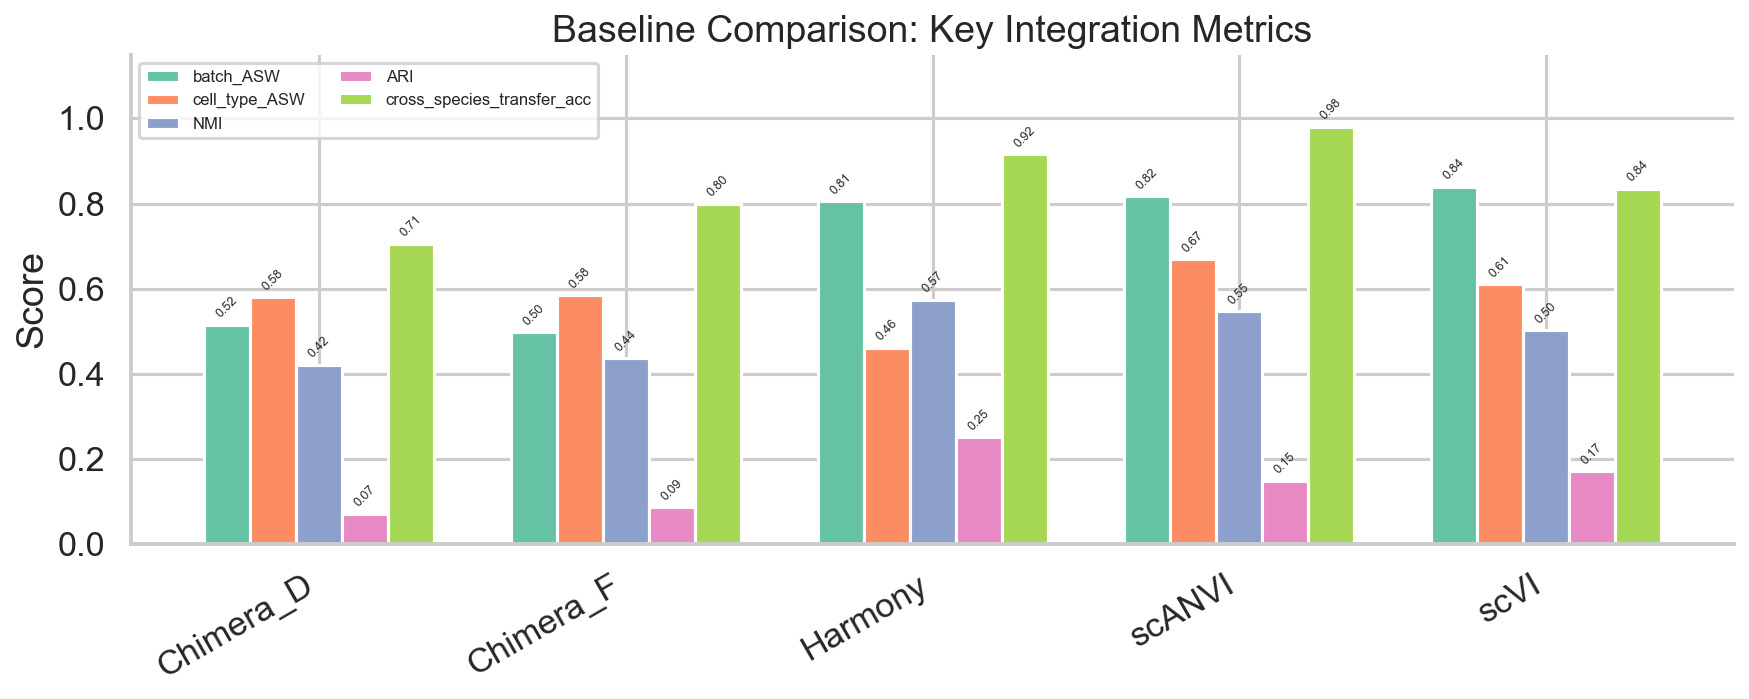

In [5]:
# Figure 1: Bar chart comparing methods across key metrics
key_metrics = ["batch_ASW", "cell_type_ASW", "NMI", "ARI", "cross_species_transfer_acc"]
available_metrics = [m for m in key_metrics if m in comparison_table.columns]

plot_df = comparison_table.set_index("method")[available_metrics].copy()

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(plot_df.index))
width = 0.15
colors = sns.color_palette("Set2", len(available_metrics))

for i, metric in enumerate(available_metrics):
    offset = (i - len(available_metrics) / 2 + 0.5) * width
    bars = ax.bar(x + offset, plot_df[metric].values, width, label=metric, color=colors[i])
    for bar, val in zip(bars, plot_df[metric].values):
        if np.isfinite(val):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.01,
                f"{val:.2f}",
                ha="center", va="bottom", fontsize=6, rotation=45,
            )

ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=30, ha="right")
ax.set_ylabel("Score")
ax.set_title("Baseline Comparison: Key Integration Metrics")
ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.set_ylim(0, 1.15)
sns.despine()
fig.tight_layout()

fig.savefig(FIGURE_DIR / "fig1_baseline_comparison_bar.pdf")
fig.savefig(FIGURE_DIR / "fig1_baseline_comparison_bar.png")
print(f"Saved: {FIGURE_DIR / 'fig1_baseline_comparison_bar.pdf'}")
plt.show()

---
## Section 2: Ablation Suite

Run the priority ablation configurations to quantify the contribution of each
Chimera v2.4 component.  Configs tested:

| Config | Description |
|--------|-------------|
| A      | Full v2.4 (default) |
| D      | No anchor (lambda_anchor=0) |
| F      | No adversarial (adv_weight=0) |
| M      | Per-gene learnable alpha (no GIN) |
| J      | No FQR (lambda_fit=0) |
| C      | No L1 sparsity (lambda_res=0) |
| H      | Higher lambda_aux=0.5 |
| B'     | Alpha frozen at conservation prior |

In [6]:
# Run ablation suite (or load from checkpoints)
ablation_configs = ["A", "D", "F", "M", "J", "C", "H", "B_prime"]
ablation_summary_path = ABLATION_DIR / "ablation_summary.csv"

if ablation_summary_path.exists():
    print("Loading pre-computed ablation results ...")
    ablation_df = pd.read_csv(ablation_summary_path)
else:
    print(f"Running ablation suite for configs: {ablation_configs}")
    print("This will take several hours ...")
    ablation_df = run_ablation_suite(
        dataset_path=str(ADATA_PATH),
        configs=ablation_configs,
        output_dir=str(ABLATION_DIR),
        max_epochs=MAX_EPOCHS,
        seed=SEED,
        species_key="species",
        batch_key="batch",
    )

print(f"\nAblation results ({len(ablation_df)} configs):")
print(ablation_df.to_string(index=False))

2026-04-19 09:20:33,337 [INFO] scripts.run_ablations: Loading dataset from ../data/processed/camex_pancreas_unified.h5ad


Running ablation suite for configs: ['A', 'D', 'F', 'M', 'J', 'C', 'H', 'B_prime']
This will take several hours ...


2026-04-19 09:20:33,446 [INFO] scripts.run_ablations: Setting up AnnData for ChimeraModel


2026-04-19 09:20:33,473 [INFO] scripts.run_ablations: === Starting ablation config A ===


2026-04-19 09:20:33,505 [INFO] chimera._model: Created ChimeraModel from config 'A'


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scvi/train/_trainrunner.py:69: UserWarning: `accelerator` has been automatically set to `cpu` although 'mps' exists. If you wish to run on mps backend, use explicitly accelerator='mps' in train function.In future releases it will become default for mps supported machines.
  accelerator, lightning_devices, device = parse_device_args(


... (77 outputs left out)

2026-04-19 17:12:50,993 [INFO] scripts.run_ablations: Ablation summary saved to ../results/validation/ablations/ablation_summary.csv


2026-04-19 17:12:50,994 [INFO] scripts.run_ablations: Full results JSON saved to ../results/validation/ablations/ablation_results.json


2026-04-19 17:12:50,995 [INFO] scripts.run_ablations: Ablation suite complete: 8/8 succeeded, 0 failed



Ablation results (8 configs):
 config  status  wall_time_s error  latent_mean_var  latent_collapsed_dims  latent_effective_dims  alpha_mean  alpha_std  alpha_frac_below_0.1  alpha_frac_above_0.9  delta_alpha_frac_positive  delta_alpha_frac_negative  delta_alpha_abs_mean
      A success  2861.027065               0.446460                      0                     10    0.801018   0.096874              0.000000              0.159252                   0.646131                   0.353869          2.456443e-03
      D success  3558.357828               0.500079                      0                     10    0.595253   0.482822              0.387093              0.578106                   0.583286                   0.416714          4.109943e-01
      F success  3519.574221               0.464255                      0                     10    0.801018   0.096858              0.000000              0.159027                   0.647370                   0.352517          2.502286e-03
     

In [7]:
# Ablation comparison table with config descriptions
config_descriptions = {
    name: cfg.get("note", "") for name, cfg in ABLATION_CONFIGS.items()
}

display_df = ablation_df.copy()
display_df["description"] = display_df["config"].map(config_descriptions)

# Reorder columns for readability
metric_cols = [
    col for col in display_df.columns
    if col not in ["config", "description", "status", "wall_time_s", "error"]
]
display_cols = ["config", "description", "status", "wall_time_s"] + metric_cols
display_df = display_df[[c for c in display_cols if c in display_df.columns]]

# Save the annotated table
display_df.to_csv(RESULTS_DIR / "ablation_comparison_annotated.csv", index=False)
print(display_df.to_string(index=False))

 config                                            description  status  wall_time_s  latent_mean_var  latent_collapsed_dims  latent_effective_dims  alpha_mean  alpha_std  alpha_frac_below_0.1  alpha_frac_above_0.9  delta_alpha_frac_positive  delta_alpha_frac_negative  delta_alpha_abs_mean
      A                                    Full v2.4 (default) success  2861.027065         0.446460                      0                     10    0.801018   0.096874              0.000000              0.159252                   0.646131                   0.353869          2.456443e-03
      D                            No anchor (lambda_anchor=0) success  3558.357828         0.500079                      0                     10    0.595253   0.482822              0.387093              0.578106                   0.583286                   0.416714          4.109943e-01
      F   No adversarial (adv_weight handled by training plan) success  3519.574221         0.464255                      0       

Saved: ../results/validation/figures/fig2_ablation_heatmap.pdf


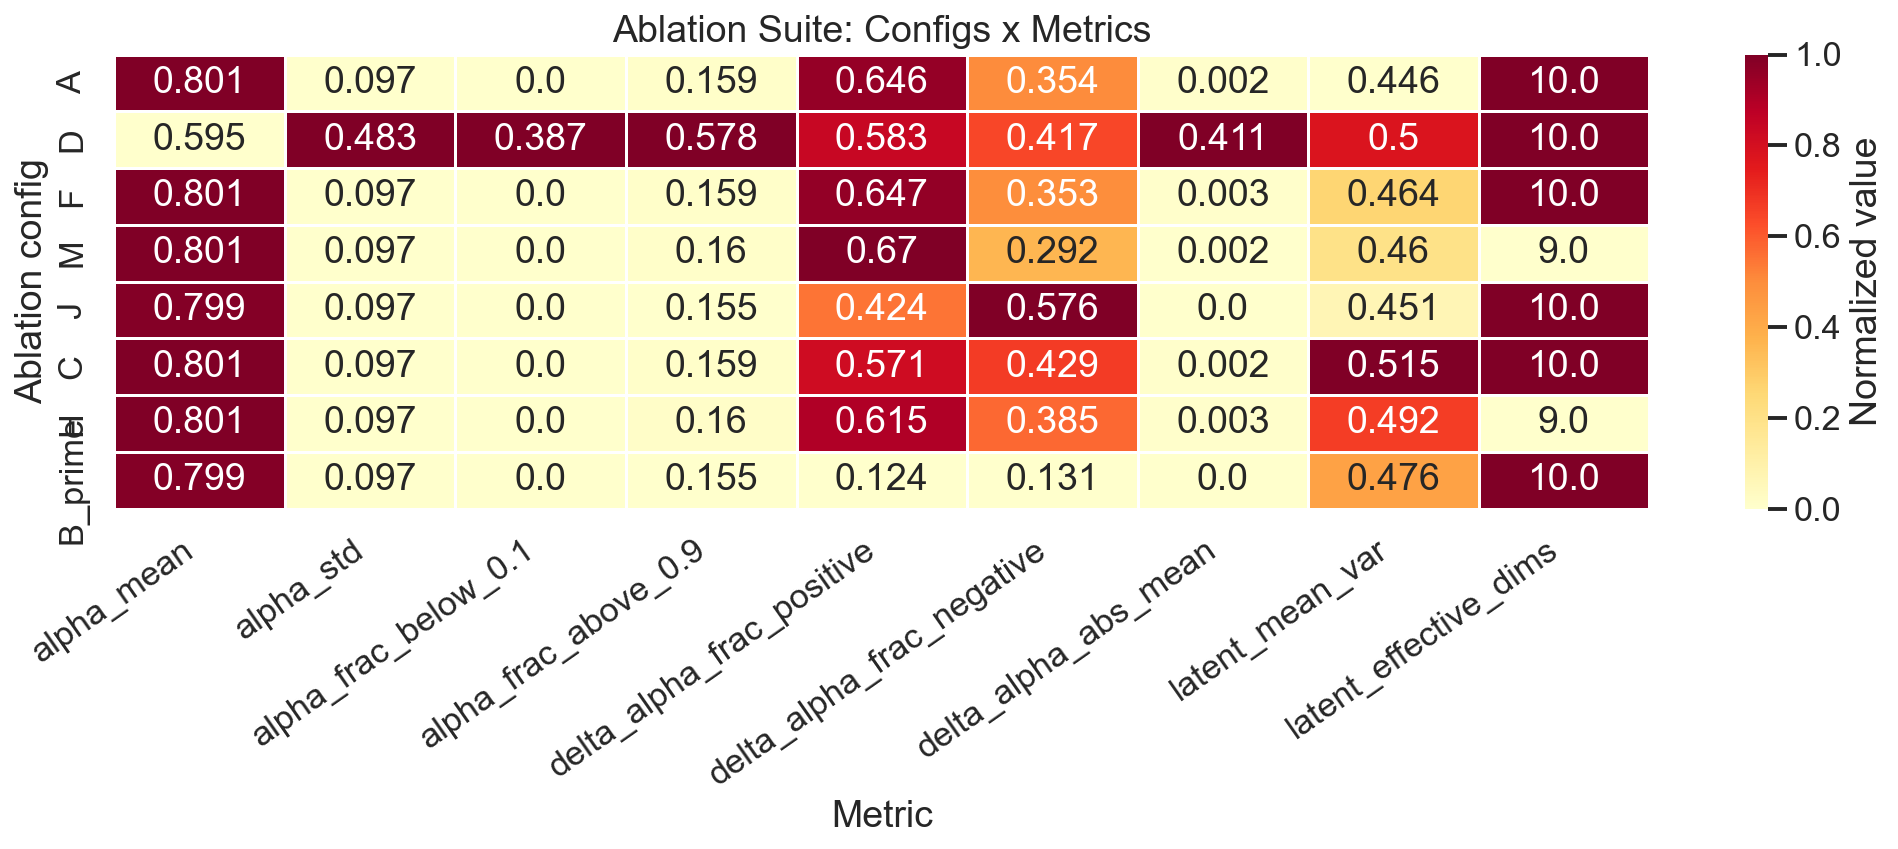

In [8]:
# Figure 2: Heatmap of ablation configs x metrics
heatmap_metrics = [
    "alpha_mean", "alpha_std", "alpha_frac_below_0.1", "alpha_frac_above_0.9",
    "delta_alpha_frac_positive", "delta_alpha_frac_negative", "delta_alpha_abs_mean",
    "latent_mean_var", "latent_effective_dims",
]
available_heatmap_metrics = [m for m in heatmap_metrics if m in ablation_df.columns]

heatmap_data = ablation_df.set_index("config")[available_heatmap_metrics].astype(float)

# Normalize each column to [0, 1] for color mapping
heatmap_norm = heatmap_data.copy()
for col in heatmap_norm.columns:
    col_min = heatmap_norm[col].min()
    col_max = heatmap_norm[col].max()
    if col_max - col_min > 1e-10:
        heatmap_norm[col] = (heatmap_norm[col] - col_min) / (col_max - col_min)
    else:
        heatmap_norm[col] = 0.5

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    heatmap_norm,
    annot=heatmap_data.round(3),
    fmt="",
    cmap="YlOrRd",
    linewidths=0.5,
    ax=ax,
    cbar_kws={"label": "Normalized value"},
)
ax.set_title("Ablation Suite: Configs x Metrics")
ax.set_ylabel("Ablation config")
ax.set_xlabel("Metric")
plt.xticks(rotation=35, ha="right")
fig.tight_layout()

fig.savefig(FIGURE_DIR / "fig2_ablation_heatmap.pdf")
fig.savefig(FIGURE_DIR / "fig2_ablation_heatmap.png")
print(f"Saved: {FIGURE_DIR / 'fig2_ablation_heatmap.pdf'}")
plt.show()

---
## Section 3: Alpha Analysis

Compare the learned alpha distributions across ablation configurations to understand
how each component shapes gene-level integration weights.

Key comparison: config **D** (no anchor, bidirectional delta-alpha expected)
vs config **J** (no FQR, one-directional delta-alpha -- FM4 failure mode).

In [9]:
# Load alpha and delta_alpha arrays for each ablation config
alpha_configs = ["D", "F", "M", "J", "A", "B_prime"]
alpha_dict = {}
delta_alpha_dict = {}
conservation_prior = adata.var["conservation_prior"].values

for cfg_name in alpha_configs:
    alpha_path = ABLATION_DIR / f"config_{cfg_name}" / "alpha.npy"
    delta_path = ABLATION_DIR / f"config_{cfg_name}" / "delta_alpha.npy"
    if alpha_path.exists():
        alpha_dict[cfg_name] = np.load(alpha_path)
        if delta_path.exists():
            delta_alpha_dict[cfg_name] = np.load(delta_path)
        else:
            delta_alpha_dict[cfg_name] = alpha_dict[cfg_name] - conservation_prior
        print(f"Config {cfg_name}: alpha mean={alpha_dict[cfg_name].mean():.4f}, "
              f"std={alpha_dict[cfg_name].std():.4f}, "
              f"delta_alpha frac_pos={(delta_alpha_dict[cfg_name] > 0).mean():.3f}")
    else:
        print(f"Config {cfg_name}: alpha.npy not found, skipping.")

print(f"\nLoaded alpha for {len(alpha_dict)} configs: {list(alpha_dict.keys())}")

Config D: alpha mean=0.5953, std=0.4828, delta_alpha frac_pos=0.583
Config F: alpha mean=0.8010, std=0.0969, delta_alpha frac_pos=0.647
Config M: alpha mean=0.8010, std=0.0969, delta_alpha frac_pos=0.670
Config J: alpha mean=0.7994, std=0.0970, delta_alpha frac_pos=0.424
Config A: alpha mean=0.8010, std=0.0969, delta_alpha frac_pos=0.646
Config B_prime: alpha mean=0.7994, std=0.0970, delta_alpha frac_pos=0.124

Loaded alpha for 6 configs: ['D', 'F', 'M', 'J', 'A', 'B_prime']


Saved: ../results/validation/figures/fig3_alpha_distributions.pdf


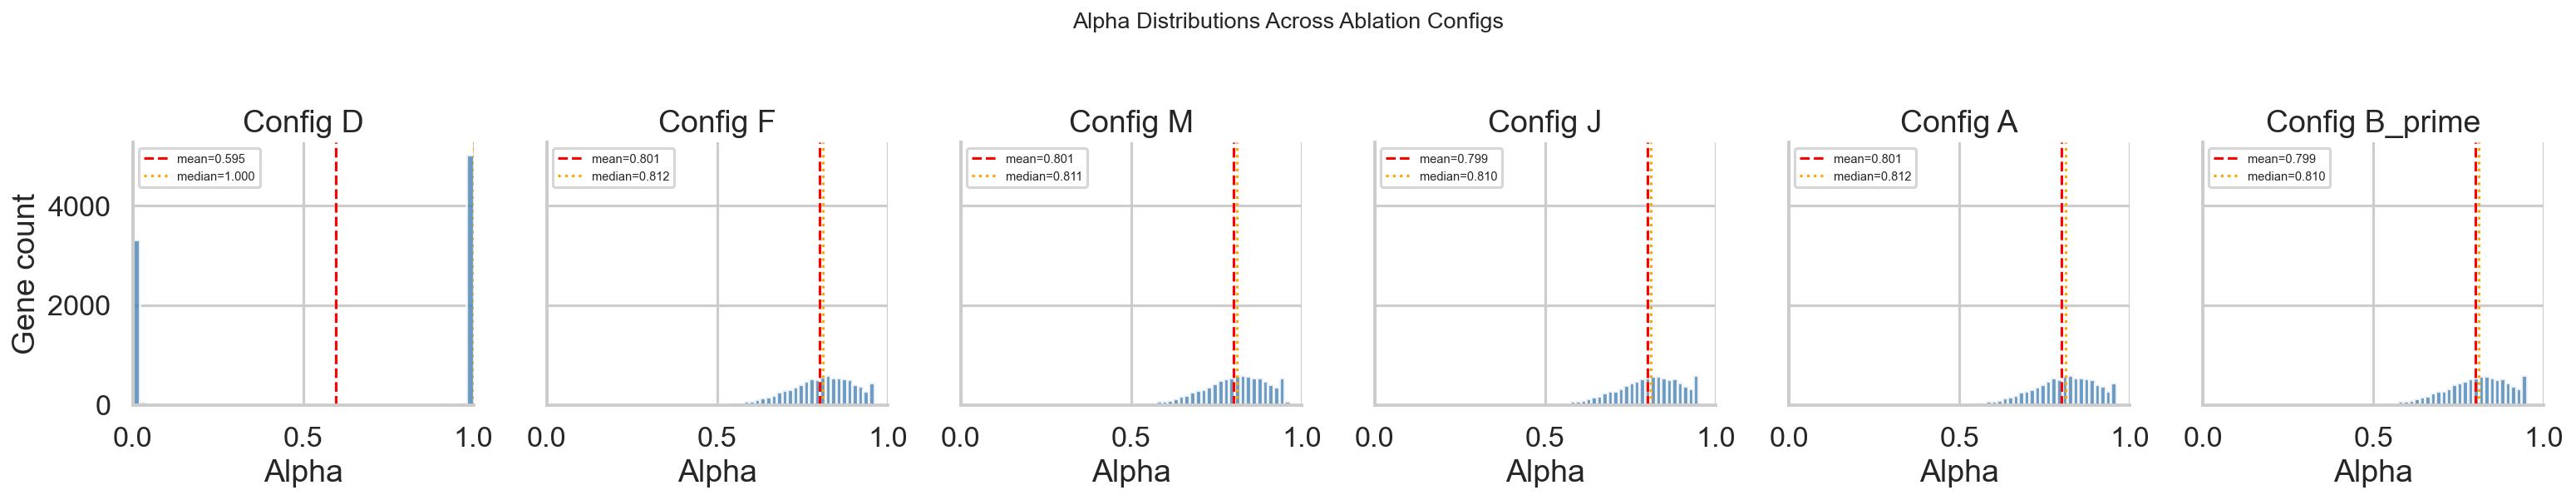

In [10]:
# Alpha distribution comparison across configs
n_configs = len(alpha_dict)
if n_configs > 0:
    fig, axes = plt.subplots(1, n_configs, figsize=(3.5 * n_configs, 4), sharey=True)
    if n_configs == 1:
        axes = [axes]

    for ax, (cfg_name, alpha_vals) in zip(axes, alpha_dict.items()):
        ax.hist(alpha_vals, bins=50, color="steelblue", edgecolor="white", alpha=0.8)
        ax.axvline(alpha_vals.mean(), color="red", linestyle="--", linewidth=1.5,
                   label=f"mean={alpha_vals.mean():.3f}")
        ax.axvline(np.median(alpha_vals), color="orange", linestyle=":", linewidth=1.5,
                   label=f"median={np.median(alpha_vals):.3f}")
        ax.set_xlabel("Alpha")
        ax.set_title(f"Config {cfg_name}")
        ax.legend(fontsize=7)
        ax.set_xlim(0, 1)

    axes[0].set_ylabel("Gene count")
    fig.suptitle("Alpha Distributions Across Ablation Configs", y=1.02, fontsize=13)
    sns.despine()
    fig.tight_layout()

    fig.savefig(FIGURE_DIR / "fig3_alpha_distributions.pdf")
    fig.savefig(FIGURE_DIR / "fig3_alpha_distributions.png")
    print(f"Saved: {FIGURE_DIR / 'fig3_alpha_distributions.pdf'}")
    plt.show()
else:
    print("No alpha arrays available for plotting.")

Saved: ../results/validation/figures/fig4_delta_alpha_D_vs_J.pdf


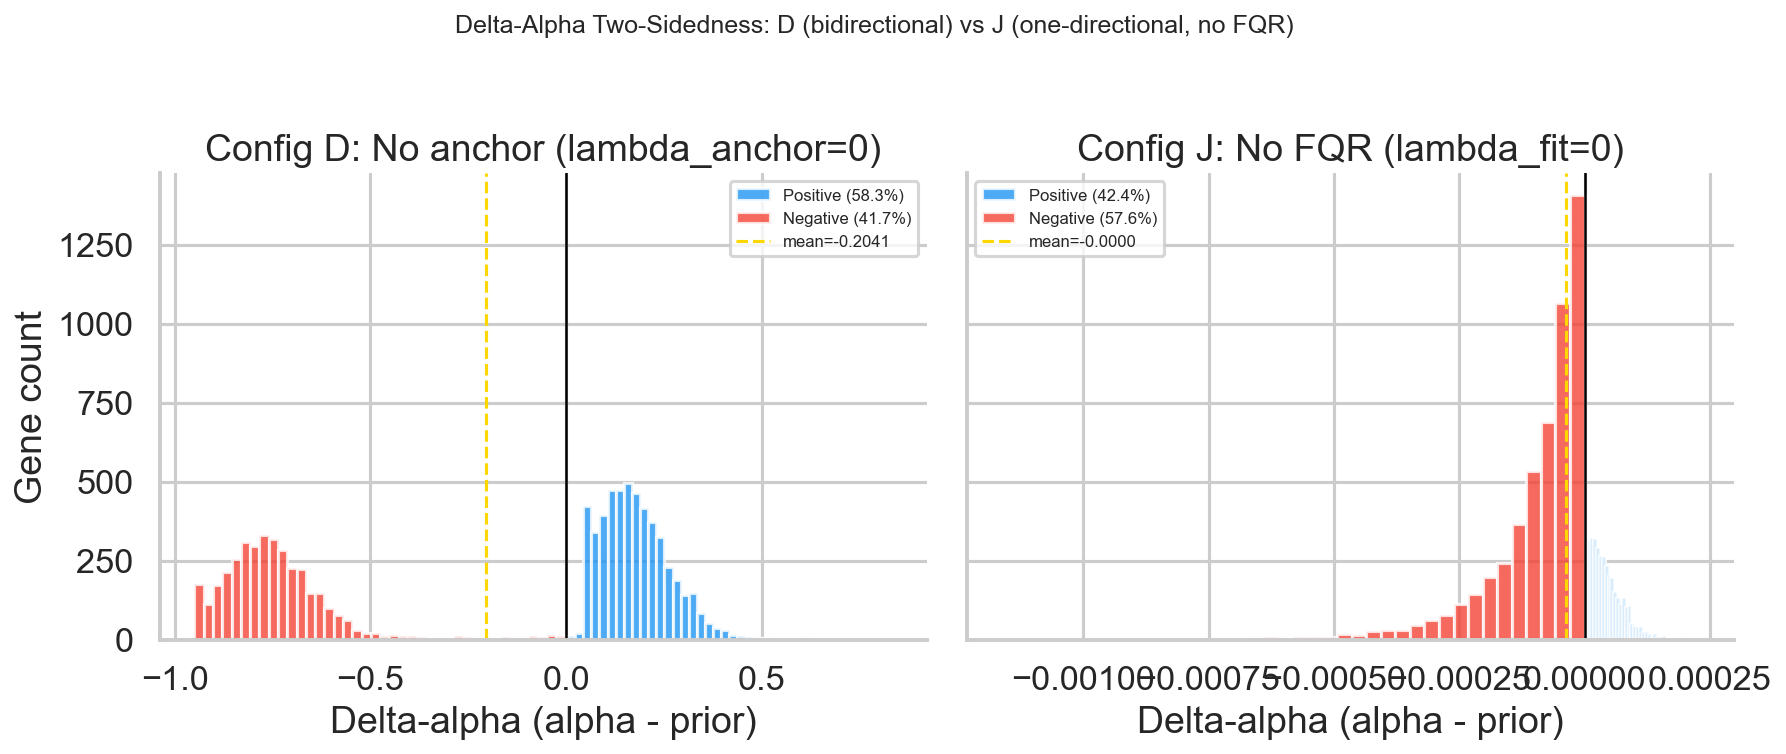


Config D:
  frac positive: 0.5833
  frac negative: 0.4167
  mean positive: 0.1773
  mean negative: -0.7381
  abs mean:      0.4110

Config J:
  frac positive: 0.4238
  frac negative: 0.5757
  mean positive: 0.0000
  mean negative: -0.0001
  abs mean:      0.0001


In [11]:
# Delta-alpha two-sidedness: Config D (bidirectional) vs Config J (one-directional)
# Config D: no anchor -- GIN corrections should still be bidirectional with FQR active
# Config J: no FQR -- FM4 predicts delta_alpha > 0 is unreachable (only negative corrections)

compare_configs = ["D", "J"]
available_compare = [c for c in compare_configs if c in delta_alpha_dict]

if len(available_compare) == 2:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

    for ax, cfg_name in zip(axes, available_compare):
        da = delta_alpha_dict[cfg_name]
        frac_pos = (da > 0).mean()
        frac_neg = (da < 0).mean()

        # Color positive and negative separately
        ax.hist(da[da >= 0], bins=40, color="#2196F3", alpha=0.8,
                label=f"Positive ({frac_pos:.1%})", edgecolor="white")
        ax.hist(da[da < 0], bins=40, color="#F44336", alpha=0.8,
                label=f"Negative ({frac_neg:.1%})", edgecolor="white")
        ax.axvline(0, color="black", linewidth=1.2, linestyle="-")
        ax.axvline(da.mean(), color="gold", linewidth=1.5, linestyle="--",
                   label=f"mean={da.mean():.4f}")
        ax.set_xlabel("Delta-alpha (alpha - prior)")
        ax.set_title(f"Config {cfg_name}: {ABLATION_CONFIGS[cfg_name].get('note', '')}")
        ax.legend(fontsize=8)

    axes[0].set_ylabel("Gene count")
    fig.suptitle("Delta-Alpha Two-Sidedness: D (bidirectional) vs J (one-directional, no FQR)",
                 y=1.02, fontsize=12)
    sns.despine()
    fig.tight_layout()

    fig.savefig(FIGURE_DIR / "fig4_delta_alpha_D_vs_J.pdf")
    fig.savefig(FIGURE_DIR / "fig4_delta_alpha_D_vs_J.png")
    print(f"Saved: {FIGURE_DIR / 'fig4_delta_alpha_D_vs_J.pdf'}")
    plt.show()

    # Quantitative summary
    for cfg_name in available_compare:
        da = delta_alpha_dict[cfg_name]
        print(f"\nConfig {cfg_name}:")
        print(f"  frac positive: {(da > 0).mean():.4f}")
        print(f"  frac negative: {(da < 0).mean():.4f}")
        print(f"  mean positive: {da[da > 0].mean():.4f}" if (da > 0).any() else "  mean positive: N/A")
        print(f"  mean negative: {da[da < 0].mean():.4f}" if (da < 0).any() else "  mean negative: N/A")
        print(f"  abs mean:      {np.abs(da).mean():.4f}")
else:
    print(f"Need both configs D and J for comparison; available: {available_compare}")

---
## Section 4: Stress Tests

Two robustness checks to verify Chimera v2.4 gracefully handles data corruption:

1. **Gene dropout test**: Randomly zero out 20% of genes and check that integration
   metrics do not catastrophically degrade.
2. **Conservation prior shuffle**: Randomize the conservation prior so it carries
   no information, and verify that alpha can still learn from data (FQR should
   compensate).

In [12]:
# Stress Test 1: Gene Dropout
# Randomly zero 20% of genes per cell and retrain, then compare metrics
print("=== Stress Test 1: Gene Dropout (20%) ===")

rng = np.random.RandomState(SEED)
adata_dropout = adata.copy()

# Create a dropout mask: for each cell, zero out 20% of genes
n_cells, n_genes = adata_dropout.X.shape
dropout_frac = 0.20
n_dropout = int(n_genes * dropout_frac)

import scipy.sparse as sp
X = adata_dropout.X
if sp.issparse(X):
    X_dense = np.array(X.todense())
else:
    X_dense = np.array(X, copy=True)

for i in range(n_cells):
    drop_idx = rng.choice(n_genes, n_dropout, replace=False)
    X_dense[i, drop_idx] = 0

adata_dropout.X = sp.csr_matrix(X_dense)
print(f"Applied {dropout_frac:.0%} gene dropout to {n_cells} cells ({n_dropout} genes per cell)")
print(f"Original total counts: {adata.X.sum():.0f}")
print(f"Dropout total counts:  {adata_dropout.X.sum():.0f}")

# Train Chimera config A on dropout data
dropout_dir = RESULTS_DIR / "stress_tests" / "gene_dropout"
dropout_dir.mkdir(parents=True, exist_ok=True)
dropout_model_path = dropout_dir / "config_A"

ChimeraModel.setup_anndata(adata_dropout, species_key="species", batch_key="batch")
model_dropout = ChimeraModel.from_config(adata_dropout, "A")
model_dropout.train(max_epochs=MAX_EPOCHS)

latent_dropout = model_dropout.get_latent_representation()
alpha_dropout = model_dropout.get_alpha()

# Store latent for metric computation
adata_dropout.obsm["X_Chimera_dropout"] = latent_dropout
np.save(dropout_dir / "alpha_dropout.npy", alpha_dropout)

print(f"\nDropout model alpha: mean={alpha_dropout.mean():.4f}, std={alpha_dropout.std():.4f}")
print(f"Dropout model latent dims with var >= 0.1: {(latent_dropout.var(axis=0) >= 0.1).sum()}/{latent_dropout.shape[1]}")

=== Stress Test 1: Gene Dropout (20%) ===


2026-04-19 17:12:57,745 [INFO] chimera._model: Created ChimeraModel from config 'A'


Applied 20% gene dropout to 22104 cells (1775 genes per cell)
Original total counts: 42836784
Dropout total counts:  34274940


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scvi/train/_trainrunner.py:69: UserWarning: `accelerator` has been automatically set to `cpu` although 'mps' exists. If you wish to run on mps backend, use explicitly accelerator='mps' in train function.In future releases it will become default for mps supported machines.
  accelerator, lightning_devices, device = parse_device_args(


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/core/optimizer.py:317: The lr scheduler dict contains the key(s) ['monitor'], but the keys will be ignored. You need to call `lr_scheduler.step()` manually in manual optimization.
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Training:   0%|          | 0/200 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.



Dropout model alpha: mean=0.8003, std=0.0969
Dropout model latent dims with var >= 0.1: 10/10


In [13]:
# Compute metrics for dropout model and compare with clean model
dropout_metrics = _compute_scib_metrics(
    adata_dropout,
    embed_key="X_Chimera_dropout",
    batch_key="species",
    label_key="cell_type",
)
dropout_xfer = cross_species_label_transfer(
    adata_dropout,
    embed_key="X_Chimera_dropout",
    species_key="species",
    label_key="cell_type",
)
dropout_metrics["cross_species_transfer_acc"] = dropout_xfer.get("mean_accuracy", float("nan"))

# Load clean config A metrics from ablation results for comparison
clean_row = ablation_df[ablation_df["config"] == "A"].iloc[0] if "A" in ablation_df["config"].values else None

print("\nGene Dropout Stress Test Results:")
print(f"{'Metric':<30} {'Dropout':>10} {'Note':>20}")
print("-" * 62)
for metric, value in sorted(dropout_metrics.items()):
    print(f"{metric:<30} {value:>10.4f}")

# Save
pd.DataFrame([dropout_metrics]).to_csv(dropout_dir / "dropout_metrics.csv", index=False)
print(f"\nSaved to {dropout_dir / 'dropout_metrics.csv'}")

2026-04-19 18:10:13,372 [WARNING] scripts.compute_metrics: scib metric kBET failed: 
'rpy2' is an optional dependency and not installed by default. Please make sure you install it manually.


mean silhouette per group:                 silhouette_score
group                           
B Plasma cells          0.527491
Cholangio               0.505847
Endothelial             0.493393
Hepatocytes             0.449245
Kupffer cells           0.430535
Macrophages             0.291010
fibroblasts             0.427730


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(labels)
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(labels)
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(labels)
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version.

2026-04-19 18:10:15,010 [WARNING] scripts.compute_metrics: scib metric ilisi_graph failed: [Errno 8] Exec format error: '/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/knn_graph/knn_graph.o'


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/metrics/isolated_labels.py:311: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  batch_per_lab = tmp.groupby(label_key).agg({batch_key: "count"})


isolated labels: no more than 1 batches per label
isolated labels: ['HsPCs', 'NK NKT and T cells']


... (4 outputs left out)

2026-04-19 18:10:35,703 [INFO] scripts.compute_metrics:   Mouse -> accuracy 0.9145 (3943 evaluable cells)


2026-04-19 18:10:36,173 [INFO] scripts.compute_metrics:   Zebrafish -> accuracy 0.0125 (5530 evaluable cells)


2026-04-19 18:10:36,174 [INFO] scripts.compute_metrics: Cross-species label transfer mean accuracy: 0.6968



Gene Dropout Stress Test Results:
Metric                            Dropout                 Note
--------------------------------------------------------------
ARI                                0.0624
NMI                                0.4073
batch_ASW                          0.4465
cLISI                                 nan
cell_type_ASW                      0.5736
cross_species_transfer_acc         0.6968
graph_connectivity                 0.6515
iLISI                                 nan
isolated_label_ASW                 0.6893
kBET                                  nan

Saved to ../results/validation/stress_tests/gene_dropout/dropout_metrics.csv


In [14]:
# Stress Test 2: Conservation Prior Shuffle
# Randomize the conservation prior so it carries no information.
# Alpha should still learn from data via FQR.
print("=== Stress Test 2: Conservation Prior Shuffle ===")

adata_shuffled = adata.copy()
original_prior = adata_shuffled.var["conservation_prior"].values.copy()
shuffled_prior = rng.permutation(original_prior)
adata_shuffled.var["conservation_prior"] = shuffled_prior

print(f"Original prior: mean={original_prior.mean():.4f}, std={original_prior.std():.4f}")
print(f"Shuffled prior: mean={shuffled_prior.mean():.4f}, std={shuffled_prior.std():.4f}")
print(f"Spearman(original, shuffled) = {spearmanr(original_prior, shuffled_prior).statistic:.4f}")

# Train Chimera config A on shuffled prior
shuffle_dir = RESULTS_DIR / "stress_tests" / "prior_shuffle"
shuffle_dir.mkdir(parents=True, exist_ok=True)

ChimeraModel.setup_anndata(adata_shuffled, species_key="species", batch_key="batch")
model_shuffled = ChimeraModel.from_config(adata_shuffled, "A")
model_shuffled.train(max_epochs=MAX_EPOCHS)

alpha_shuffled = model_shuffled.get_alpha()

# Compare learned alpha from shuffled prior vs original alpha from config A
alpha_clean_path = ABLATION_DIR / "config_A" / "alpha.npy"
if alpha_clean_path.exists():
    alpha_clean = np.load(alpha_clean_path)
    rho_clean_shuffled, p_clean_shuffled = spearmanr(alpha_clean, alpha_shuffled)
    print(f"\nSpearman(alpha_clean, alpha_shuffled) = {rho_clean_shuffled:.4f} (p={p_clean_shuffled:.2e})")
    print("Interpretation: if FQR works, alpha_shuffled should still correlate with")
    print("alpha_clean because the data signal overcomes the uninformative prior.")
else:
    alpha_clean = None
    print("Clean config A alpha not found; skipping direct comparison.")

np.save(shuffle_dir / "alpha_shuffled.npy", alpha_shuffled)
print(f"\nShuffled model alpha: mean={alpha_shuffled.mean():.4f}, std={alpha_shuffled.std():.4f}")

# Save summary
summary = {
    "alpha_shuffled_mean": float(alpha_shuffled.mean()),
    "alpha_shuffled_std": float(alpha_shuffled.std()),
    "spearman_clean_vs_shuffled": float(rho_clean_shuffled) if alpha_clean is not None else None,
    "spearman_pvalue": float(p_clean_shuffled) if alpha_clean is not None else None,
}
with open(shuffle_dir / "prior_shuffle_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(f"Saved to {shuffle_dir / 'prior_shuffle_summary.json'}")

2026-04-19 18:10:36,332 [INFO] chimera._model: Created ChimeraModel from config 'A'


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scvi/train/_trainrunner.py:69: UserWarning: `accelerator` has been automatically set to `cpu` although 'mps' exists. If you wish to run on mps backend, use explicitly accelerator='mps' in train function.In future releases it will become default for mps supported machines.
  accelerator, lightning_devices, device = parse_device_args(


=== Stress Test 2: Conservation Prior Shuffle ===
Original prior: mean=0.7994, std=0.0970
Shuffled prior: mean=0.7994, std=0.0970
Spearman(original, shuffled) = 0.0045


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/core/optimizer.py:317: The lr scheduler dict contains the key(s) ['monitor'], but the keys will be ignored. You need to call `lr_scheduler.step()` manually in manual optimization.
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Training:   0%|          | 0/200 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.



Spearman(alpha_clean, alpha_shuffled) = 0.0105 (p=3.22e-01)
Interpretation: if FQR works, alpha_shuffled should still correlate with
alpha_clean because the data signal overcomes the uninformative prior.

Shuffled model alpha: mean=0.8011, std=0.0966
Saved to ../results/validation/stress_tests/prior_shuffle/prior_shuffle_summary.json


---
## Section 5: scVI Post-hoc Comparison

Compare Chimera's learned alpha with scVI-derived per-gene F-statistics.
High F-statistic means high between-species variance (divergent gene);
low alpha means the model treats the gene as divergent.  

**Expected:** negative Spearman correlation between F-stat and alpha,
confirming that Chimera's learned gene weights agree with an independent
measure of cross-species divergence.

In [15]:
# Load scVI model for F-statistic computation
import scvi as scvi_pkg

scvi_model_dir = BASELINE_DIR / "scvi_model"

if scvi_model_dir.exists():
    adata_fstat = adata.copy()
    scvi_pkg.model.SCVI.setup_anndata(adata_fstat, batch_key="species")
    scvi_model = scvi_pkg.model.SCVI.load(str(scvi_model_dir), adata=adata_fstat)
    print("Loaded scVI model from checkpoint.")

    # Compute per-gene F-statistics
    f_stats = compute_scvi_f_statistics(adata_fstat, scvi_model)
    print(f"F-statistics: shape={f_stats.shape}, median={np.median(f_stats):.2f}, "
          f"max={f_stats.max():.2f}")
else:
    print(f"scVI model not found at {scvi_model_dir}. Training from scratch ...")
    adata_fstat = adata.copy()
    scvi_pkg.model.SCVI.setup_anndata(adata_fstat, batch_key="species")
    scvi_model = scvi_pkg.model.SCVI(adata_fstat, n_latent=10)
    scvi_model.train(max_epochs=MAX_EPOCHS, early_stopping=True)
    scvi_model.save(str(scvi_model_dir), overwrite=True)
    f_stats = compute_scvi_f_statistics(adata_fstat, scvi_model)
    print(f"Trained scVI and computed F-statistics: shape={f_stats.shape}")

INFO     File ../results/validation/baselines/scvi_model/model.pt already downloaded                               


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scvi/model/base/_base_model.py:796: UserWarning: `accelerator` has been automatically set to `cpu` although 'mps' exists. If you wish to run on mps backend, use explicitly accelerator='mps' in train function.In future releases it will become default for mps supported machines.
  _, _, device = parse_device_args(
2026-04-19 19:08:40,761 [INFO] scripts.train_baselines: Computing per-gene scVI F-statistics ...


Loaded scVI model from checkpoint.


F-statistics: shape=(8879,), median=9243.11, max=1007096.06


In [16]:
# Compare Chimera alpha (config A) with scVI F-statistics
alpha_a_path = ABLATION_DIR / "config_A" / "alpha.npy"

if alpha_a_path.exists():
    alpha_a = np.load(alpha_a_path)
else:
    # Fallback: use alpha from any available Chimera model
    available_alpha_configs = list(alpha_dict.keys())
    fallback_cfg = available_alpha_configs[0] if available_alpha_configs else None
    if fallback_cfg:
        alpha_a = alpha_dict[fallback_cfg]
        print(f"Config A alpha not found; using config {fallback_cfg} as fallback.")
    else:
        raise FileNotFoundError("No alpha arrays available for comparison.")

comparison = compare_fstats_with_alpha(f_stats, alpha_a)
print(f"\nSpearman correlation: rho = {comparison['spearman_r']:.4f}")
print(f"P-value:             p = {comparison['p_value']:.2e}")
print(f"N genes used:        n = {comparison['n_genes']}")

2026-04-19 19:08:47,740 [INFO] scripts.train_baselines: Spearman(scVI F-stat, Chimera alpha) = 0.1274 (p=1.91e-33, n=8879 genes)



Spearman correlation: rho = 0.1274
P-value:             p = 1.91e-33
N genes used:        n = 8879


Saved: ../results/validation/figures/fig5_alpha_vs_fstat.pdf


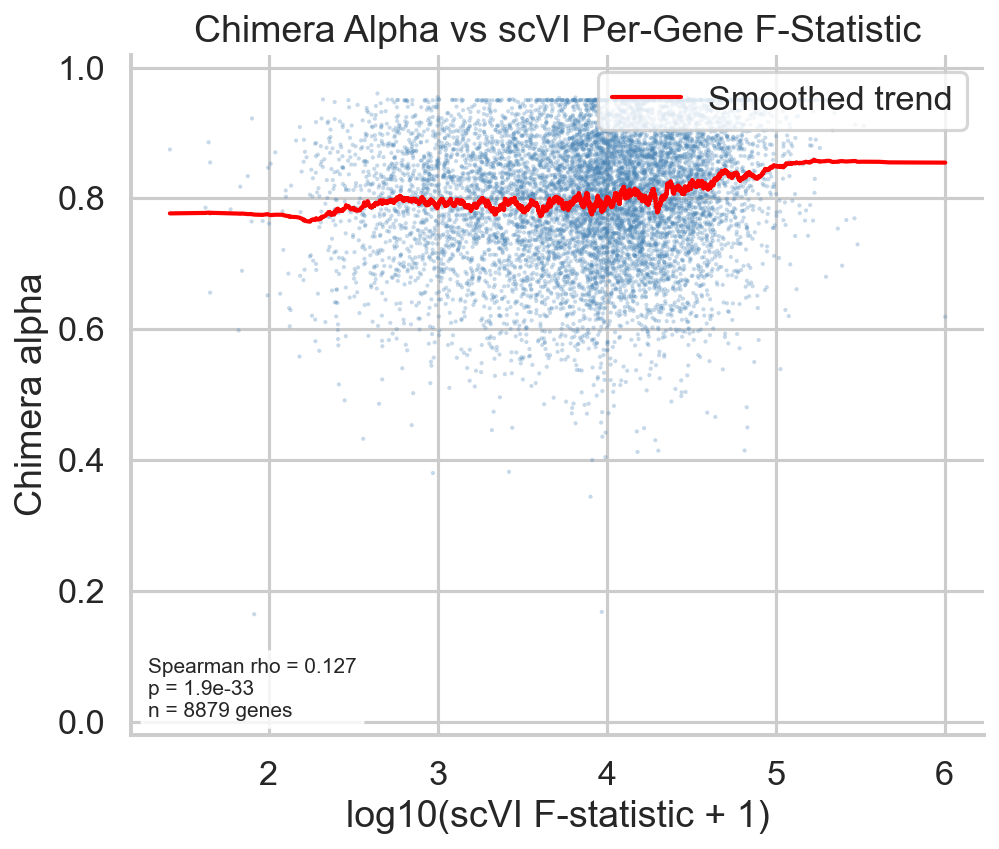

In [17]:
# Figure 5: Scatter plot -- Chimera alpha vs scVI F-statistic
mask = np.isfinite(f_stats) & np.isfinite(alpha_a) & (f_stats > 0)
f_valid = f_stats[mask]
alpha_valid = alpha_a[mask]

fig, ax = plt.subplots(figsize=(7, 6))
scatter = ax.scatter(
    np.log10(f_valid + 1),
    alpha_valid,
    s=4,
    alpha=0.3,
    c="steelblue",
    edgecolors="none",
    rasterized=True,
)

# Trend line (LOWESS)
from scipy.ndimage import uniform_filter1d
sort_idx = np.argsort(np.log10(f_valid + 1))
x_sorted = np.log10(f_valid + 1)[sort_idx]
y_sorted = alpha_valid[sort_idx]
window = max(len(y_sorted) // 50, 10)
y_smooth = uniform_filter1d(y_sorted.astype(float), size=window)
ax.plot(x_sorted, y_smooth, color="red", linewidth=2, label="Smoothed trend")

# Annotation
rho = comparison["spearman_r"]
pval = comparison["p_value"]
ax.text(
    0.02, 0.02,
    f"Spearman rho = {rho:.3f}\np = {pval:.1e}\nn = {comparison['n_genes']} genes",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="bottom",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
)

ax.set_xlabel("log10(scVI F-statistic + 1)")
ax.set_ylabel("Chimera alpha")
ax.set_title("Chimera Alpha vs scVI Per-Gene F-Statistic")
ax.legend(loc="upper right")
ax.set_ylim(-0.02, 1.02)
sns.despine()
fig.tight_layout()

fig.savefig(FIGURE_DIR / "fig5_alpha_vs_fstat.pdf")
fig.savefig(FIGURE_DIR / "fig5_alpha_vs_fstat.png")
print(f"Saved: {FIGURE_DIR / 'fig5_alpha_vs_fstat.pdf'}")
plt.show()

---
## Save All Results

In [18]:
# Consolidate and save all validation outputs
print("=" * 60)
print("Validation & Ablation Analysis -- Summary")
print("=" * 60)

# Save consolidated comparison table
comparison_table.to_csv(RESULTS_DIR / "baseline_comparison.csv", index=False)
print(f"  Baseline comparison: {RESULTS_DIR / 'baseline_comparison.csv'}")

# Save ablation table
ablation_df.to_csv(RESULTS_DIR / "ablation_summary.csv", index=False)
print(f"  Ablation summary:    {RESULTS_DIR / 'ablation_summary.csv'}")

# Save F-stat comparison
fstat_results = {
    "spearman_r": comparison["spearman_r"],
    "p_value": comparison["p_value"],
    "n_genes": comparison["n_genes"],
}
with open(RESULTS_DIR / "fstat_alpha_comparison.json", "w") as f:
    json.dump(fstat_results, f, indent=2)
print(f"  F-stat comparison:   {RESULTS_DIR / 'fstat_alpha_comparison.json'}")

# List all saved figures
figures = sorted(FIGURE_DIR.glob("*.pdf"))
print(f"\nFigures saved ({len(figures)}):")
for fig_path in figures:
    print(f"  {fig_path.name}")

# List all saved tables
tables = sorted(RESULTS_DIR.glob("*.csv"))
print(f"\nTables saved ({len(tables)}):")
for tbl_path in tables:
    print(f"  {tbl_path.name}")

print("\nValidation notebook complete.")

Validation & Ablation Analysis -- Summary
  Baseline comparison: ../results/validation/baseline_comparison.csv
  Ablation summary:    ../results/validation/ablation_summary.csv
  F-stat comparison:   ../results/validation/fstat_alpha_comparison.json

Figures saved (5):
  fig1_baseline_comparison_bar.pdf
  fig2_ablation_heatmap.pdf
  fig3_alpha_distributions.pdf
  fig4_delta_alpha_D_vs_J.pdf
  fig5_alpha_vs_fstat.pdf

Tables saved (3):
  ablation_comparison_annotated.csv
  ablation_summary.csv
  baseline_comparison.csv

Validation notebook complete.
